# 01 – Data Understanding and Exploratory Data Analysis
**IT3091 Machine Learning · Group 2026-DS-02 · Bank Marketing**

Goal: understand what each row and column means, how the target behaves, which data-quality issues exist,
and **how each finding affects the prediction task** (pre-contact ranking of clients by subscription likelihood).

The data is **not modified** here; all fixes happen in `02_preprocessing.ipynb`.

| Section | Content |
|---|---|
| 1 | Setup and loading |
| 2 | Data dictionary |
| 3 | What does a row represent? |
| 4 | Target variable |
| 5 | Numeric features – distributions and outliers |
| 6 | Categorical features – distributions |
| 7 | Features vs target (subscription rates, statistical tests) |
| 8 | Data quality: `unknown`, duplicates, placeholders, consistency, rare categories |
| 9 | Correlation and multicollinearity |
| 10 | Time pattern |
| 11 | Leakage evidence: `duration` |
| 12 | Summary of findings |

## 1. Setup and loading

In [1]:
import sys, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LinearRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
config.FIGURES.mkdir(exist_ok=True)

def save_fig(name):
    """Save the current figure to figures/ (for the report) and display it."""
    plt.tight_layout()
    plt.savefig(config.FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
df = pd.read_csv(config.RAW_FILE, sep=config.CSV_SEPARATOR)
assert hashlib.sha256(config.RAW_FILE.read_bytes()).hexdigest() == config.RAW_FILE_SHA256, "Wrong dataset file"
assert df.shape == config.EXPECTED_SHAPE

ORIGINAL_COLS = df.columns.tolist()
FEATURES = [c for c in ORIGINAL_COLS if c != config.TARGET]
NUM_COLS = df[FEATURES].select_dtypes("number").columns.tolist()
CAT_COLS = [c for c in FEATURES if c not in NUM_COLS]

# Numeric copy of the target (1 = yes) used only for computing rates in this notebook
df["y_num"] = (df[config.TARGET] == config.POSITIVE_CLASS).astype(int)
OVERALL_RATE = df["y_num"].mean()

print("Shape:", df[ORIGINAL_COLS].shape)
print(f"Overall subscription rate: {OVERALL_RATE:.2%}")
print(f"Numeric features ({len(NUM_COLS)}):", NUM_COLS)
print(f"Categorical features ({len(CAT_COLS)}):", CAT_COLS)

Shape: (41188, 21)
Overall subscription rate: 11.27%
Numeric features (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


## 2. Data dictionary
Descriptions come from the official documentation (`data/raw/bank-additional-names.txt`).
**Known before call?** is the key column for leakage: the model may only use information the bank has *before* calling a client.

In [3]:
DESCRIPTIONS = {
    "age": "Client age in years",
    "job": "Type of job",
    "marital": "Marital status ('divorced' includes widowed)",
    "education": "Education level",
    "default": "Has credit in default?",
    "housing": "Has a housing loan?",
    "loan": "Has a personal loan?",
    "contact": "Contact communication type",
    "month": "Month of the last contact",
    "day_of_week": "Weekday of the last contact",
    "duration": "Duration of the last contact in seconds",
    "campaign": "Number of contacts in this campaign for this client (includes the last contact)",
    "pdays": "Days since the client was last contacted in a previous campaign (999 = never contacted)",
    "previous": "Number of contacts before this campaign for this client",
    "poutcome": "Outcome of the previous marketing campaign",
    "emp.var.rate": "Employment variation rate (quarterly indicator)",
    "cons.price.idx": "Consumer price index (monthly indicator)",
    "cons.conf.idx": "Consumer confidence index (monthly indicator)",
    "euribor3m": "Euribor 3-month interest rate (daily indicator)",
    "nr.employed": "Number of employees in the economy, thousands (quarterly indicator)",
    "y": "TARGET - has the client subscribed to a term deposit?",
}
KIND = {
    "age": "numeric (discrete)", "job": "nominal", "marital": "nominal", "education": "ordinal",
    "default": "binary + unknown", "housing": "binary + unknown", "loan": "binary + unknown",
    "contact": "binary", "month": "cyclical / nominal", "day_of_week": "cyclical / nominal",
    "duration": "numeric (continuous)", "campaign": "numeric (count)", "pdays": "numeric with placeholder",
    "previous": "numeric (count)", "poutcome": "nominal",
    "emp.var.rate": "numeric (continuous)", "cons.price.idx": "numeric (continuous)",
    "cons.conf.idx": "numeric (continuous)", "euribor3m": "numeric (continuous)",
    "nr.employed": "numeric (continuous)", "y": "binary target",
}
KNOWN_BEFORE_CALL = {
    **{c: "Yes" for c in config.CLIENT_FEATURES},
    "contact": "Yes (planned channel)",
    "month": "Yes (planned call date)",
    "day_of_week": "Yes (planned call date)",
    "duration": "NO - only known after the call (leakage)",
    "campaign": "Partly - grows during the campaign",
    "pdays": "Yes", "previous": "Yes", "poutcome": "Yes",
    **{c: "Yes (public indicator)" for c in config.ECONOMIC_FEATURES},
    "y": "Target",
}
GROUP = {c: g for g, cols in {
    "client": config.CLIENT_FEATURES, "contact": config.CONTACT_FEATURES,
    "campaign history": config.CAMPAIGN_FEATURES, "economic context": config.ECONOMIC_FEATURES,
    "target": [config.TARGET]}.items() for c in cols}

rows = []
for c in ORIGINAL_COLS:
    s = df[c]
    if pd.api.types.is_numeric_dtype(s):
        values = f"{s.min():g} to {s.max():g}"
    else:
        values = ", ".join(sorted(s.unique()))
    n_unknown = int((s.astype(str) == config.MISSING_TOKEN).sum())
    rows.append({
        "column": c, "group": GROUP[c], "type": KIND[c], "description": DESCRIPTIONS[c],
        "values / range": values, "n_unique": s.nunique(),
        "n_unknown": n_unknown, "pct_unknown": round(100 * n_unknown / len(df), 2),
        "known_before_call": KNOWN_BEFORE_CALL[c],
    })
data_dictionary = pd.DataFrame(rows).set_index("column")
data_dictionary.to_csv(config.DOCS / "data_dictionary.csv")
with pd.option_context("display.max_colwidth", 70):
    display(data_dictionary)

,group,type,description,values / range,n_unique,n_unknown,pct_unknown,known_before_call
column,,,,,,,,
age,client,numeric (discrete),Client age in years,17 to 98,78,0,0.00,Yes
job,client,nominal,Type of job,"admin., blue-collar, entrepreneur, housemaid, management, retired,...",12,330,0.80,Yes
marital,client,nominal,Marital status ('divorced' includes widowed),"divorced, married, single, unknown",4,80,0.19,Yes
education,client,ordinal,Education level,"basic.4y, basic.6y, basic.9y, high.school, illiterate, professiona...",8,1731,4.20,Yes
default,client,binary + unknown,Has credit in default?,"no, unknown, yes",3,8597,20.87,Yes
housing,client,binary + unknown,Has a housing loan?,"no, unknown, yes",3,990,2.40,Yes
loan,client,binary + unknown,Has a personal loan?,"no, unknown, yes",3,990,2.40,Yes
contact,contact,binary,Contact communication type,"cellular, telephone",2,0,0.00,Yes (planned channel)
month,contact,cyclical / nominal,Month of the last contact,"apr, aug, dec, jul, jun, mar, may, nov, oct, sep",10,0,0.00,Yes (planned call date)


## 3. What does a row represent?
The documentation says the data is *"ordered by date (from May 2008 to November 2010)"* and that more than one
contact to the same client was often needed. There is **no client ID**, so we check what we can:
duplicates, and whether rows really are in date order.

In [4]:
features_only = df[FEATURES]
n_dup_full = df[ORIGINAL_COLS].duplicated().sum()
n_dup_feat = features_only.duplicated().sum()

# Identical feature values but different target -> label conflicts
conflicts = (df[ORIGINAL_COLS].groupby(FEATURES, dropna=False)[config.TARGET]
             .nunique().gt(1).sum())

print(f"Exact duplicate rows (all 21 columns):     {n_dup_full}")
print(f"Duplicate rows on the 20 features only:    {n_dup_feat}")
print(f"Feature combinations with conflicting y:   {conflicts}")
df[df[ORIGINAL_COLS].duplicated(keep=False)].sort_values(FEATURES).head(6)

Exact duplicate rows (all 21 columns):     12
Duplicate rows on the 20 features only:    12
Feature combinations with conflicting y:   0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,y_num
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no,0
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no,0
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no,0
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no,0


In [5]:
# Month blocks in row order: if rows are date-ordered, months appear in calendar sequence and restart each year
month_blocks = df.loc[df["month"].ne(df["month"].shift()), "month"].tolist()
print(f"Number of month blocks in row order: {len(month_blocks)}")
print(" -> ".join(month_blocks))

Number of month blocks in row order: 26
may -> jun -> jul -> aug -> oct -> nov -> dec -> mar -> apr -> may -> jun -> jul -> aug -> sep -> oct -> nov -> dec -> mar -> apr -> may -> jun -> jul -> aug -> sep -> oct -> nov


In [6]:
# Reconstruct an approximate year from the date ordering (EDA helper only - NOT used as a model feature).
# A new year starts whenever the calendar month number goes backwards.
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_num = df["month"].map({m: i for i, m in enumerate(MONTH_ORDER, start=1)})
df["eda_year"] = 2008 + (month_num.diff() < 0).cumsum()
df["eda_period"] = df["eda_year"].astype(str) + "-" + month_num.astype(str).str.zfill(2)

months_present = [m for m in MONTH_ORDER if m in df["month"].unique()]
year_month = pd.crosstab(df["eda_year"], df["month"]).reindex(columns=months_present)
year_month["total"] = year_month.sum(axis=1)
year_month

month,mar,apr,may,jun,jul,aug,sep,oct,nov,dec,total
eda_year,,,,,,,,,,,
2008,0,0,7763,4374,6685,5175,0,67,3616,10,27690
2009,282,2458,5794,715,178,770,267,447,357,172,11440
2010,264,174,212,229,311,233,303,204,128,0,2058


## 4. Target variable

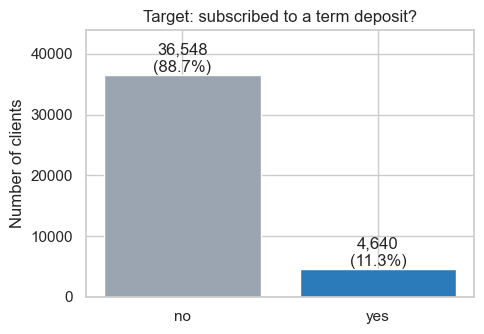

Imbalance ratio (no : yes) = 7.9 : 1
A model that always predicts 'no' would score 88.73% accuracy but find 0 of the 4,640 subscribers.


In [7]:
counts = df[config.TARGET].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#9aa5b1", "#2b7bba"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_title("Target: subscribed to a term deposit?")
ax.set_ylabel("Number of clients")
ax.set_ylim(0, counts.max() * 1.2)
save_fig("fig01_target_distribution")

print(f"Imbalance ratio (no : yes) = {counts['no'] / counts['yes']:.1f} : 1")
print(f"A model that always predicts 'no' would score {counts['no'] / len(df):.2%} accuracy "
      f"but find 0 of the {counts['yes']:,} subscribers.")

## 5. Numeric features – distributions and outliers

In [8]:
num_summary = df[NUM_COLS].describe().T
num_summary["skew"] = df[NUM_COLS].skew()
num_summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skew
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000,0.785
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000,3.263
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000,4.763
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000,-4.922
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000,3.832
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400,-0.724
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767,-0.231
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900,0.303
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045,-0.709
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100,-1.044


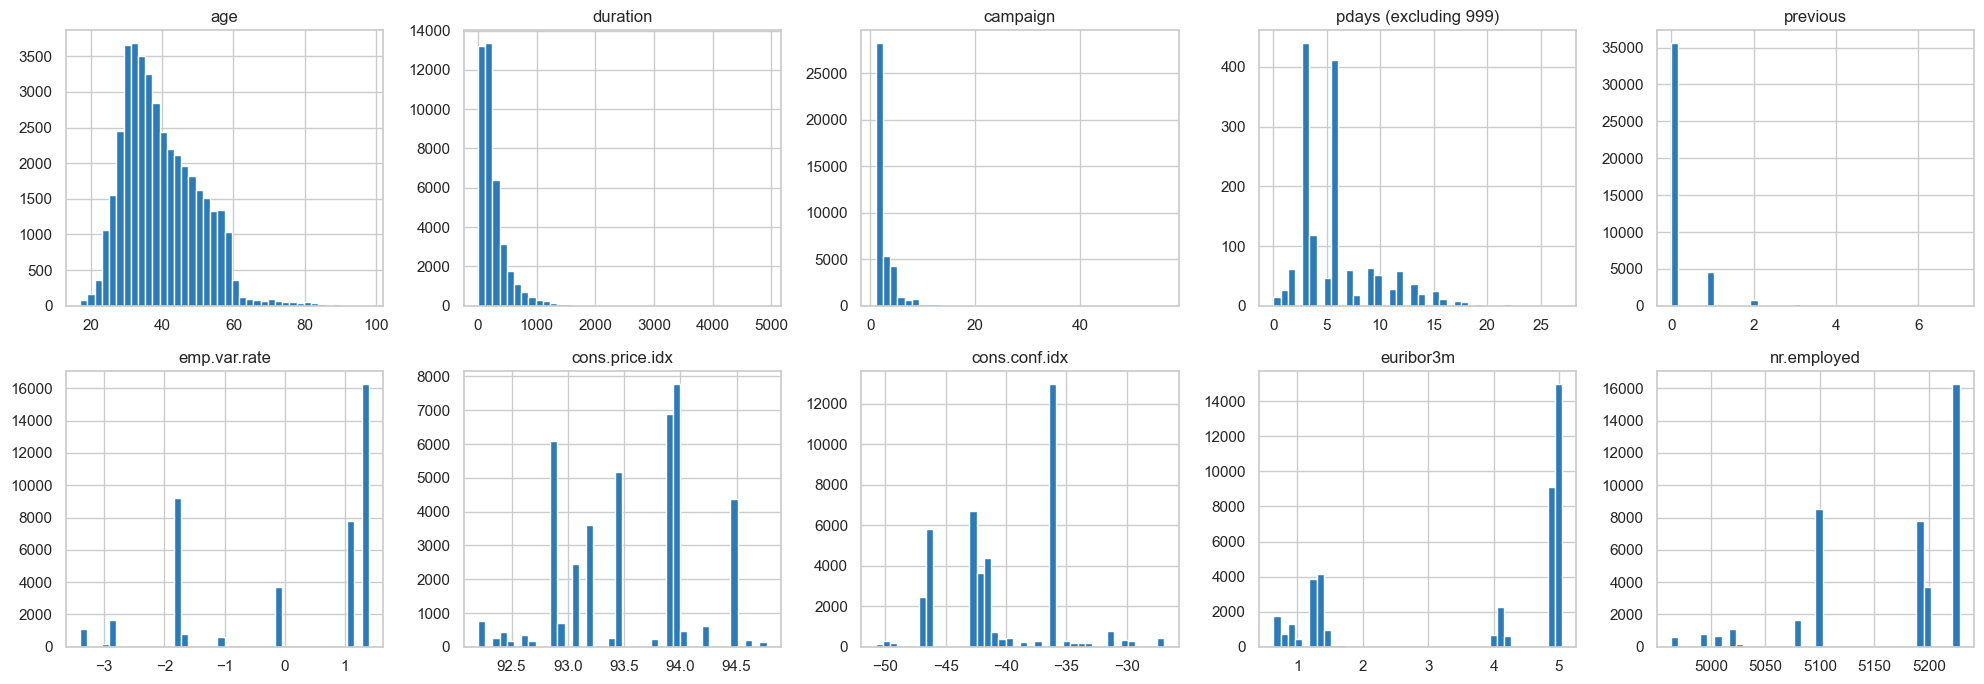

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.flat, NUM_COLS):
    data = df[c]
    title = c
    if c == "pdays":
        data = data[data != config.PDAYS_NOT_CONTACTED]
        title = "pdays (excluding 999)"
    ax.hist(data, bins=40, color="#2b7bba", edgecolor="white")
    ax.set_title(title)
for ax in axes.flat[len(NUM_COLS):]:
    ax.axis("off")
save_fig("fig02_numeric_histograms")

In [10]:
# Outliers by the 1.5 x IQR rule (pdays excluded because 999 is a placeholder, not a measurement)
rows = []
for c in [c for c in NUM_COLS if c != "pdays"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"feature": c, "lower_fence": lo, "upper_fence": hi, "n_outliers": n_out,
                 "pct_outliers": round(100 * n_out / len(df), 2), "max": df[c].max()})
pd.DataFrame(rows).set_index("feature")

,lower_fence,upper_fence,n_outliers,pct_outliers,max
feature,,,,,
age,9.5000,69.5000,469,1.14,98.000
duration,-223.5000,644.5000,2963,7.19,4918.000
campaign,-2.0000,6.0000,2406,5.84,56.000
previous,0.0000,0.0000,5625,13.66,7.000
emp.var.rate,-6.6000,6.2000,0,0.00,1.400
cons.price.idx,91.6965,95.3725,0,0.00,94.767
cons.conf.idx,-52.1500,-26.9500,447,1.09,-26.900
euribor3m,-4.0815,10.3865,0,0.00,5.045
nr.employed,4905.6000,5421.6000,0,0.00,5228.100


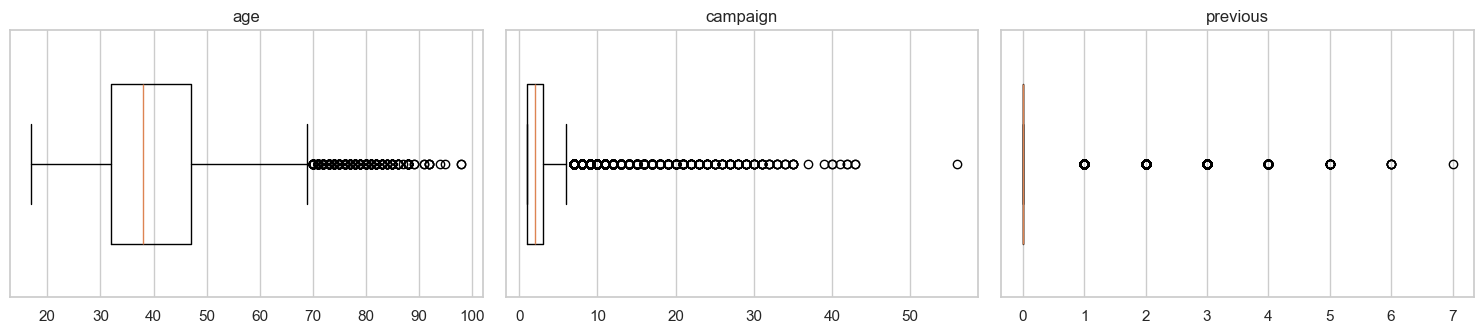

campaign value counts (top values):
campaign
1     17642
2     10570
3      5341
4      2651
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
Clients contacted more than 10 times in this campaign: 869


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, ["age", "campaign", "previous"]):
    ax.boxplot(df[c], vert=False, widths=0.6)
    ax.set_title(c)
    ax.set_yticks([])
save_fig("fig03_numeric_boxplots")

print("campaign value counts (top values):")
print(df["campaign"].value_counts().sort_index().head(12).to_string())
print(f"Clients contacted more than 10 times in this campaign: {(df['campaign'] > 10).sum()}")

In [28]:
# Are the IQR "outliers" errors, or do they carry information about the target?
rows = []
for c in ["age", "campaign", "previous", "cons.conf.idx"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    is_out = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)
    rows.append({"feature": c, "n_outliers": int(is_out.sum()),
                 "outlier_values": f"{df.loc[is_out, c].min():g} to {df.loc[is_out, c].max():g}",
                 "rate_if_outlier": round(100 * df.loc[is_out, "y_num"].mean(), 2),
                 "rate_if_normal": round(100 * df.loc[~is_out, "y_num"].mean(), 2)})
pd.DataFrame(rows).set_index("feature")

,n_outliers,outlier_values,rate_if_outlier,rate_if_normal
feature,,,,
age,469,70 to 98,47.12,10.85
campaign,2406,7 to 56,4.61,11.68
previous,5625,1 to 7,26.65,8.83
cons.conf.idx,447,-26.9 to -26.9,40.27,10.95


**Interpretation of outliers**

- **All flagged values are realistic** (ages 70–98, up to 56 calls, up to 7 previous contacts). None are data-entry errors, so **no rows are removed**.
- **`age` > 69.5 (469 clients):** subscription rate ≈ 47% vs ≈ 11% for the rest. Older clients are a high-response group, so removing them would delete real signal.
- **`campaign` > 6 calls (2,406 clients):** rate ≈ 4.6% vs ≈ 11.7%. Response falls as calls increase, so repeated calling has diminishing returns. The extreme tail (up to 56) is sparse, so **capping** (e.g. at 10) is proposed to protect Logistic Regression.
- **`previous`:** 86% of clients have 0, so the IQR collapses to 0 and *every* previously contacted client is flagged. The IQR rule is not meaningful here. These clients subscribe at ≈ 27% vs ≈ 9%.
- **`cons.conf.idx`:** all 447 "outliers" have the same value (−26.9), i.e. one month's national indicator, not an error.

*Handling is decided and applied in `02_preprocessing.ipynb` (Step 3).*

## 6. Categorical features – distributions

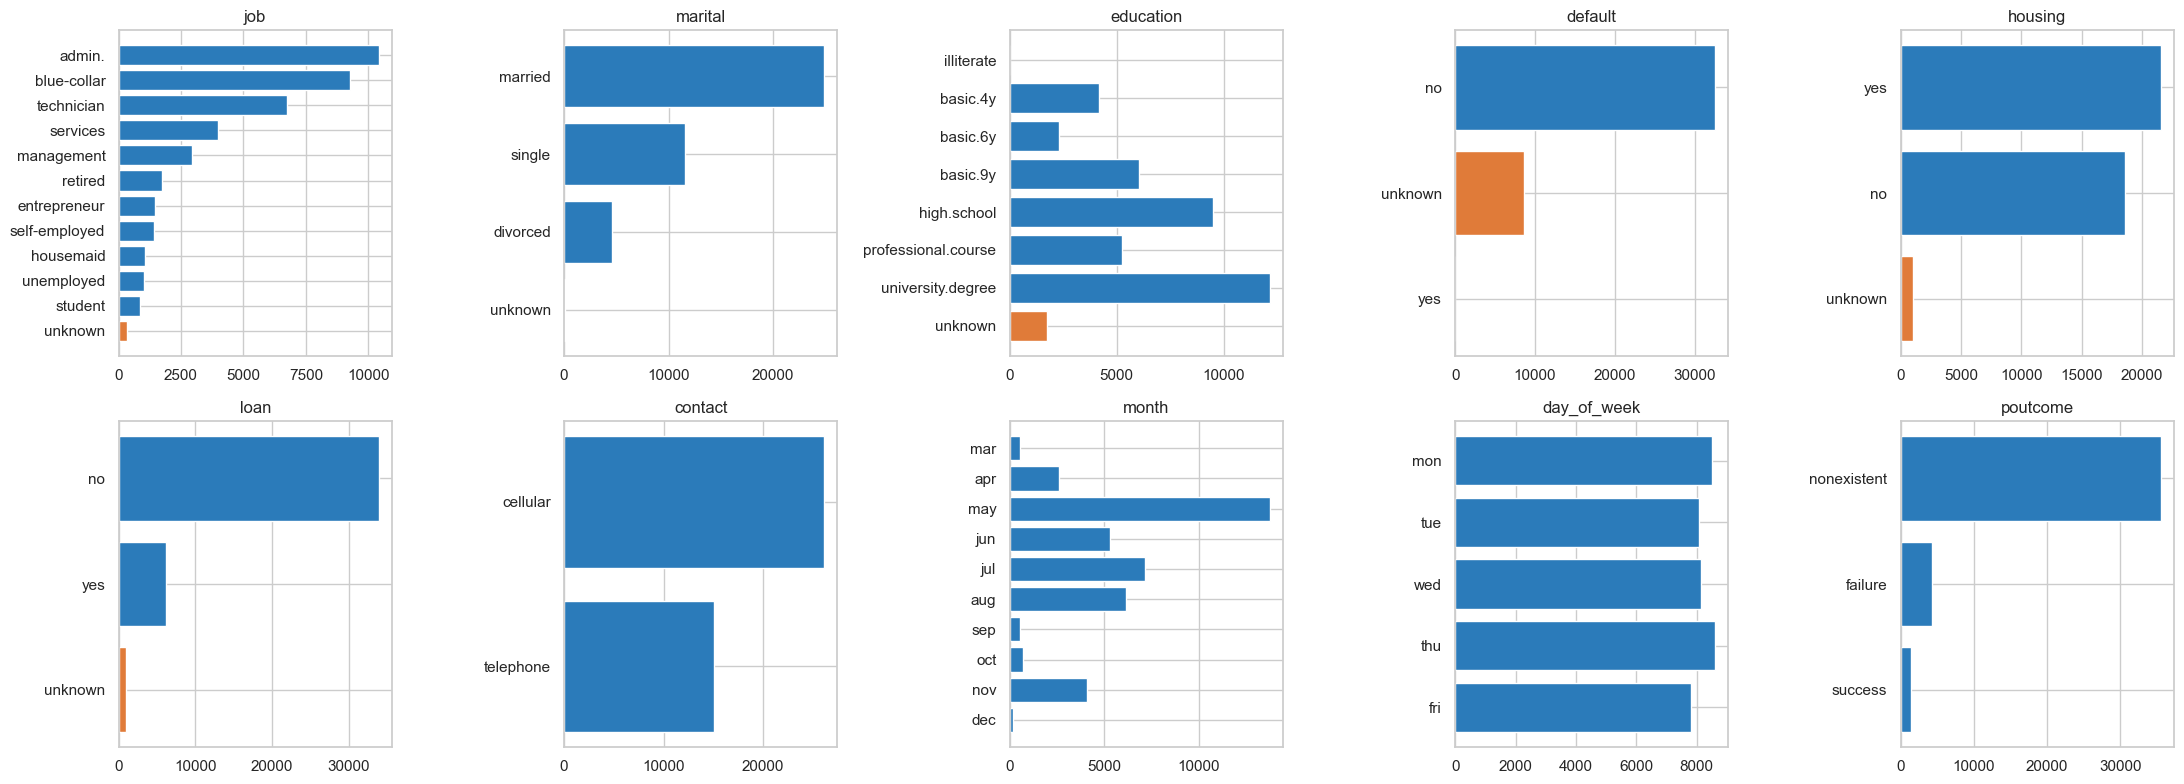

Orange bars = 'unknown' (missing) values.


In [12]:
ORDERS = {
    "month": [m for m in MONTH_ORDER if m in df["month"].unique()],
    "day_of_week": ["mon", "tue", "wed", "thu", "fri"],
    "education": ["illiterate", "basic.4y", "basic.6y", "basic.9y", "high.school",
                  "professional.course", "university.degree", "unknown"],
}

def category_order(col):
    return ORDERS.get(col, df[col].value_counts().index.tolist())

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.flat, CAT_COLS):
    vc = df[c].value_counts().reindex(category_order(c))
    colors = ["#e07b39" if k == config.MISSING_TOKEN else "#2b7bba" for k in vc.index]
    ax.barh(vc.index.astype(str), vc.values, color=colors)
    ax.invert_yaxis()
    ax.set_title(c)
save_fig("fig04_categorical_counts")
print("Orange bars = 'unknown' (missing) values.")

## 7. Features vs target
### 7.1 Subscription rate per category
Bars show the share of clients who subscribed in each category; the dashed line is the overall rate (≈11.3%).
The count `n` matters: rates from small groups are less reliable.

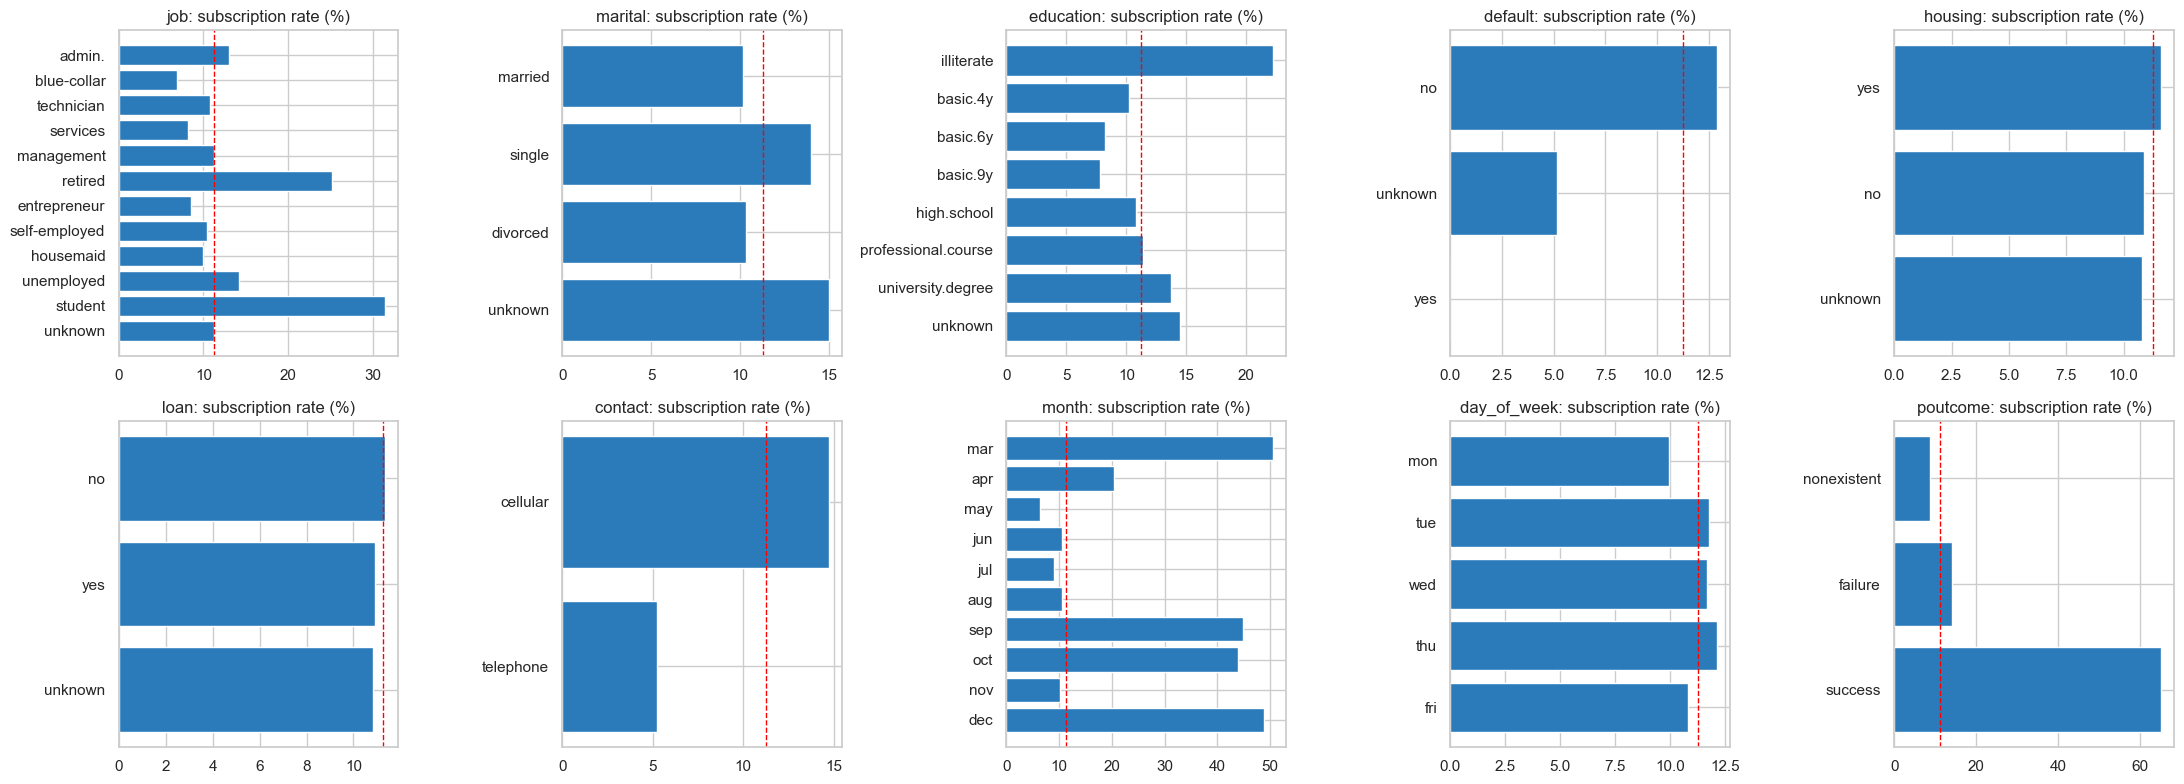

In [13]:
def rate_table(col, data=df):
    t = data.groupby(col, observed=True)["y_num"].agg(n="size", subscribed="sum", rate="mean")
    t["rate"] = (t["rate"] * 100).round(2)
    t["lift_vs_overall"] = (t["rate"] / (100 * OVERALL_RATE)).round(2)
    return t

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.flat, CAT_COLS):
    t = rate_table(c).reindex(category_order(c))
    ax.barh(t.index.astype(str), t["rate"], color="#2b7bba")
    ax.axvline(100 * OVERALL_RATE, color="red", ls="--", lw=1)
    ax.invert_yaxis()
    ax.set_title(f"{c}: subscription rate (%)")
save_fig("fig05_categorical_subscription_rates")

In [14]:
for c in CAT_COLS:
    print(f"\n=== {c} ===")
    print(rate_table(c).reindex(category_order(c)).to_string())


=== job ===
                   n  subscribed   rate  lift_vs_overall
job                                                     
admin.         10422        1352  12.97             1.15
blue-collar     9254         638   6.89             0.61
technician      6743         730  10.83             0.96
services        3969         323   8.14             0.72
management      2924         328  11.22             1.00
retired         1720         434  25.23             2.24
entrepreneur    1456         124   8.52             0.76
self-employed   1421         149  10.49             0.93
housemaid       1060         106  10.00             0.89
unemployed      1014         144  14.20             1.26
student          875         275  31.43             2.79
unknown          330          37  11.21             1.00

=== marital ===
              n  subscribed   rate  lift_vs_overall
marital                                            
married   24928        2532  10.16             0.90
single    11568 

### 7.2 Strength of association (categorical features)
Chi-square test of independence with the target, and **Cramér's V** as an effect size
(0 = no association, 1 = perfect). With 41k rows almost everything is "significant", so Cramér's V is more informative than the p-value.

In [15]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p, v

rows = []
for c in CAT_COLS:
    chi2, p, v = cramers_v(df[c], df[config.TARGET])
    rows.append({"feature": c, "chi2": round(chi2, 1), "p_value": p, "cramers_v": round(v, 3)})
assoc_cat = pd.DataFrame(rows).set_index("feature").sort_values("cramers_v", ascending=False)
assoc_cat

,chi2,p_value,cramers_v
feature,,,
poutcome,4230.5,0.000000e+00,0.320
month,3101.1,0.000000e+00,0.274
job,961.2,4.189763e-199,0.153
contact,862.3,1.525986e-189,0.145
default,406.6,5.161958e-89,0.099
education,193.1,3.305189e-38,0.068
marital,122.7,2.068015e-26,0.055
day_of_week,26.1,2.958482e-05,0.025
housing,5.7,5.829448e-02,0.012


### 7.3 Numeric features vs target
Mann-Whitney U test (no normality assumption) and the **single-feature ROC-AUC**: how well the feature alone
ranks subscribers above non-subscribers (0.5 = no better than random, 1.0 = perfect).

In [16]:
rows = []
for c in NUM_COLS:
    yes_vals = df.loc[df["y_num"] == 1, c]
    no_vals = df.loc[df["y_num"] == 0, c]
    _, p = stats.mannwhitneyu(yes_vals, no_vals)
    auc = roc_auc_score(df["y_num"], df[c])
    rows.append({"feature": c, "median_yes": yes_vals.median(), "median_no": no_vals.median(),
                 "mann_whitney_p": p, "auc": round(auc, 3),
                 "auc_strength": round(max(auc, 1 - auc), 3),
                 "direction": "higher -> more yes" if auc > 0.5 else "lower -> more yes"})
assoc_num = pd.DataFrame(rows).set_index("feature").sort_values("auc_strength", ascending=False)
assoc_num

,median_yes,median_no,mann_whitney_p,auc,auc_strength,direction
feature,,,,,,
duration,449.000,163.500,0.000000e+00,0.818,0.818,higher -> more yes
nr.employed,5099.100,5195.800,0.000000e+00,0.251,0.749,lower -> more yes
euribor3m,1.266,4.857,0.000000e+00,0.257,0.743,lower -> more yes
emp.var.rate,-1.800,1.100,0.000000e+00,0.283,0.717,lower -> more yes
cons.price.idx,93.200,93.918,9.572609e-136,0.389,0.611,lower -> more yes
previous,0.000,0.000,0.000000e+00,0.609,0.609,higher -> more yes
pdays,999.000,999.000,0.000000e+00,0.403,0.597,lower -> more yes
campaign,2.000,2.000,3.418527e-38,0.445,0.555,lower -> more yes
cons.conf.idx,-40.400,-41.800,5.901951e-17,0.537,0.537,higher -> more yes


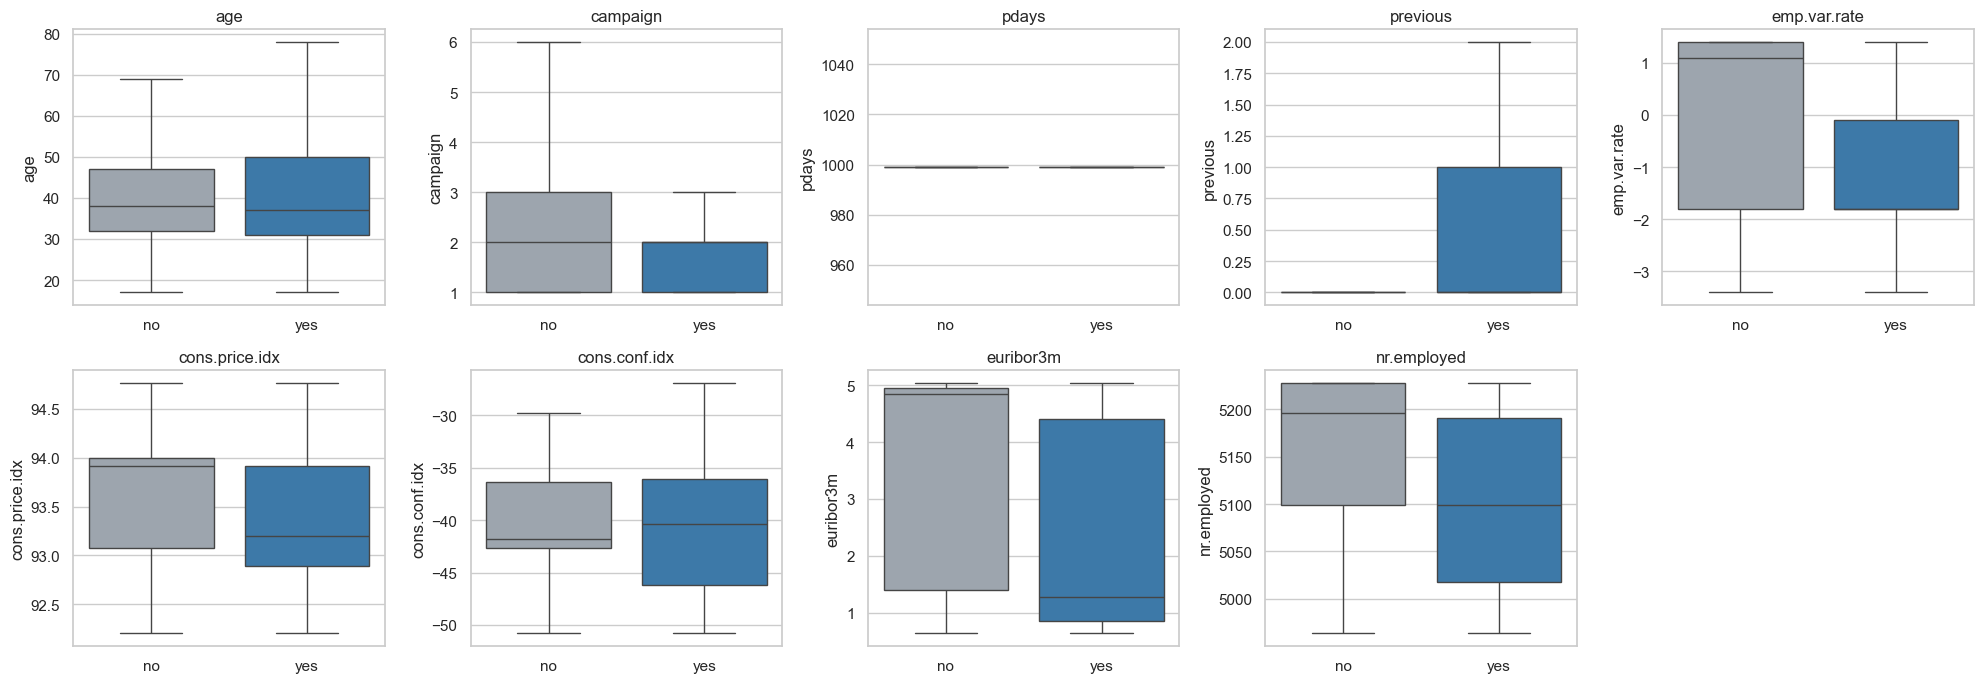

In [17]:
plot_cols = [c for c in NUM_COLS if c != "duration"]   # duration is analysed separately in Section 11
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.flat, plot_cols):
    sns.boxplot(data=df, x=config.TARGET, y=c, hue=config.TARGET, order=["no", "yes"],
                palette={"no": "#9aa5b1", "yes": "#2b7bba"}, legend=False, ax=ax, showfliers=False)
    ax.set_title(c)
    ax.set_xlabel("")
for ax in axes.flat[len(plot_cols):]:
    ax.axis("off")
save_fig("fig06_numeric_by_target")

### 7.4 Binned rates for key numeric features

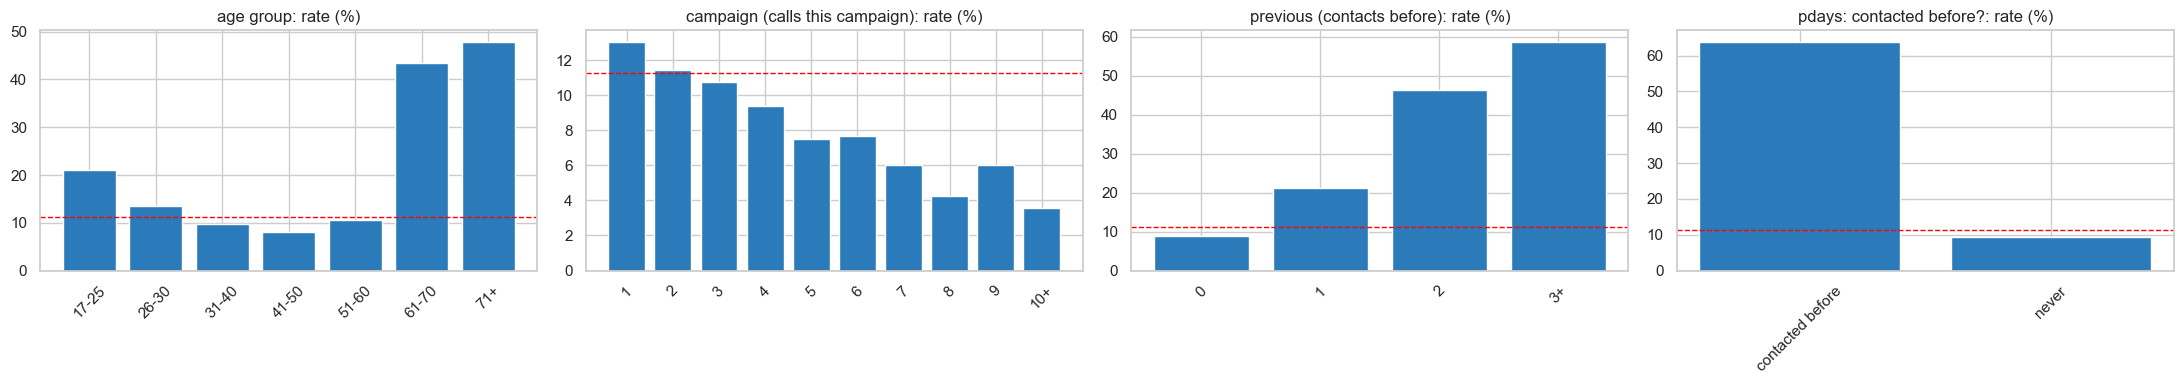


=== age group ===
           n  subscribed   rate  lift_vs_overall
age                                             
17-25   1666         349  20.95             1.86
26-30   5717         775  13.56             1.20
31-40  16385        1597   9.75             0.87
41-50  10240         837   8.17             0.73
51-60   6270         668  10.65             0.95
61-70    488         212  43.44             3.86
71+      422         202  47.87             4.25

=== campaign (calls this campaign) ===
              n  subscribed   rate  lift_vs_overall
campaign                                           
1         17642        2300  13.04             1.16
2         10570        1211  11.46             1.02
3          5341         574  10.75             0.95
4          2651         249   9.39             0.83
5          1599         120   7.50             0.67
6           979          75   7.66             0.68
7           629          38   6.04             0.54
8           400          17   4.

In [18]:
age_bins = pd.cut(df["age"], bins=[16, 25, 30, 40, 50, 60, 70, 100],
                  labels=["17-25", "26-30", "31-40", "41-50", "51-60", "61-70", "71+"])
campaign_capped = df["campaign"].clip(upper=10).astype(str).replace({"10": "10+"})
campaign_order = [str(i) for i in range(1, 10)] + ["10+"]
previous_capped = df["previous"].clip(upper=3).astype(str).replace({"3": "3+"})
previously_contacted = np.where(df["pdays"] == config.PDAYS_NOT_CONTACTED, "never", "contacted before")

binned = {
    "age group": rate_table(age_bins),
    "campaign (calls this campaign)": rate_table(campaign_capped).reindex(campaign_order),
    "previous (contacts before)": rate_table(previous_capped),
    "pdays: contacted before?": rate_table(previously_contacted),
}
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, (name, t) in zip(axes, binned.items()):
    ax.bar(t.index.astype(str), t["rate"], color="#2b7bba")
    ax.axhline(100 * OVERALL_RATE, color="red", ls="--", lw=1)
    ax.set_title(f"{name}: rate (%)")
    ax.tick_params(axis="x", rotation=45)
save_fig("fig07_binned_subscription_rates")

for name, t in binned.items():
    print(f"\n=== {name} ===")
    print(t.to_string())

## 8. Data quality
### 8.1 `unknown` values
Missing values are not blank; they are coded as the category `"unknown"`. Important question:
**is "unknown" itself related to the target?** If yes, it carries information and should be kept as its own category rather than imputed.

In [19]:
rows = []
for c in CAT_COLS:
    is_unk = df[c] == config.MISSING_TOKEN
    if is_unk.any():
        rows.append({"feature": c, "n_unknown": int(is_unk.sum()),
                     "pct_unknown": round(100 * is_unk.mean(), 2),
                     "rate_if_unknown": round(100 * df.loc[is_unk, "y_num"].mean(), 2),
                     "rate_if_known": round(100 * df.loc[~is_unk, "y_num"].mean(), 2)})
unknown_table = pd.DataFrame(rows).set_index("feature").sort_values("n_unknown", ascending=False)
print(f"Rows with at least one 'unknown': {(df[CAT_COLS] == config.MISSING_TOKEN).any(axis=1).sum():,} "
      f"({(df[CAT_COLS] == config.MISSING_TOKEN).any(axis=1).mean():.1%})")
unknown_table

Rows with at least one 'unknown': 10,700 (26.0%)


,n_unknown,pct_unknown,rate_if_unknown,rate_if_known
feature,,,,
default,8597,20.87,5.15,12.88
education,1731,4.20,14.50,11.12
housing,990,2.40,10.81,11.28
loan,990,2.40,10.81,11.28
job,330,0.80,11.21,11.27
marital,80,0.19,15.00,11.26


In [20]:
print("default value counts:")
print(df["default"].value_counts().to_string())
print("\nhousing vs loan 'unknown' overlap:")
pd.crosstab(df["housing"], df["loan"])

default value counts:
default
no         32588
unknown     8597
yes            3

housing vs loan 'unknown' overlap:


loan,no,unknown,yes
housing,,,
no,16065,0,2557
unknown,0,990,0
yes,17885,0,3691


### 8.2 Consistency of the previous-campaign fields (`pdays`, `previous`, `poutcome`)

In [21]:
never = df["pdays"] == config.PDAYS_NOT_CONTACTED
checks = {
    "pdays = 999 (never contacted)": int(never.sum()),
    "previous = 0": int((df["previous"] == 0).sum()),
    "poutcome = nonexistent": int((df["poutcome"] == "nonexistent").sum()),
    "pdays = 999 BUT previous > 0": int((never & (df["previous"] > 0)).sum()),
    "pdays != 999 BUT previous = 0": int((~never & (df["previous"] == 0)).sum()),
    "poutcome = nonexistent BUT previous > 0": int(((df["poutcome"] == "nonexistent") & (df["previous"] > 0)).sum()),
}
print(pd.Series(checks).to_string())
print("\npoutcome among rows with pdays = 999 but previous > 0:")
print(df.loc[never & (df["previous"] > 0), "poutcome"].value_counts().to_string())

pdays = 999 (never contacted)              39673
previous = 0                               35563
poutcome = nonexistent                     35563
pdays = 999 BUT previous > 0                4110
pdays != 999 BUT previous = 0                  0
poutcome = nonexistent BUT previous > 0        0

poutcome among rows with pdays = 999 but previous > 0:
poutcome
failure    4110


### 8.3 Rare categories (< 0.5% of rows)

In [22]:
rows = []
for c in CAT_COLS:
    vc = df[c].value_counts()
    for cat, n in vc[vc / len(df) < 0.005].items():
        rows.append({"feature": c, "category": cat, "n": n,
                     "subscription_rate": round(100 * df.loc[df[c] == cat, "y_num"].mean(), 2)})
pd.DataFrame(rows)

,feature,category,n,subscription_rate
0,marital,unknown,80,15.00
1,education,illiterate,18,22.22
2,default,yes,3,0.00
3,month,dec,182,48.90


## 9. Correlation and multicollinearity
Spearman correlation (robust to skew and outliers). Highly correlated inputs are a problem for **Logistic Regression**
(unstable coefficients), not much for tree models. The Variance Inflation Factor (VIF) measures this: VIF > 10 is usually treated as severe.

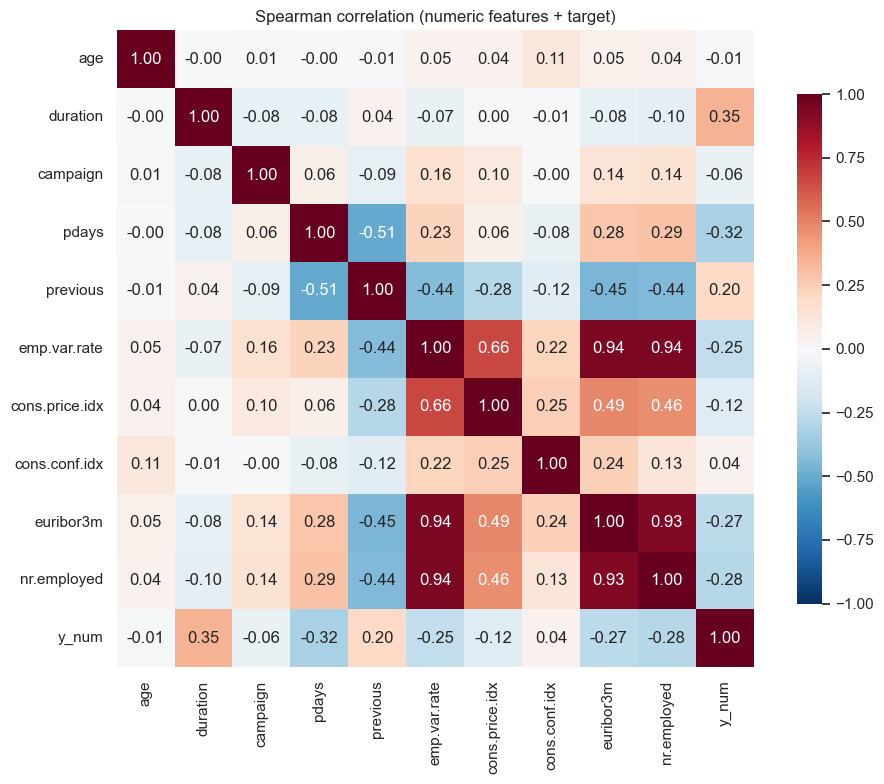

In [23]:
corr = df[NUM_COLS + ["y_num"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation (numeric features + target)")
save_fig("fig08_correlation_heatmap")

In [24]:
def vif_table(data):
    rows = []
    for c in data.columns:
        others = data.drop(columns=c)
        r2 = LinearRegression().fit(others, data[c]).score(others, data[c])
        rows.append({"feature": c, "VIF": round(1 / (1 - r2), 1) if r2 < 1 else np.inf})
    return pd.DataFrame(rows).set_index("feature").sort_values("VIF", ascending=False)

vif_cols = [c for c in NUM_COLS if c not in ("duration", "pdays")]
print("VIF of numeric model inputs (excluding duration and the pdays placeholder):")
vif_table(df[vif_cols])

VIF of numeric model inputs (excluding duration and the pdays placeholder):


,VIF
feature,
euribor3m,64.3
emp.var.rate,33.1
nr.employed,31.6
cons.price.idx,6.3
cons.conf.idx,2.6
previous,1.3
age,1.0
campaign,1.0


## 10. Time pattern
Rows are in date order, so we can look at how the subscription rate and the economy changed over the 2008–2010 period
(the reconstructed `eda_year` from Section 3 is used here only for analysis). This matters for **validation design**:
if the data changes a lot over time, a random split may give an optimistic picture of future performance.

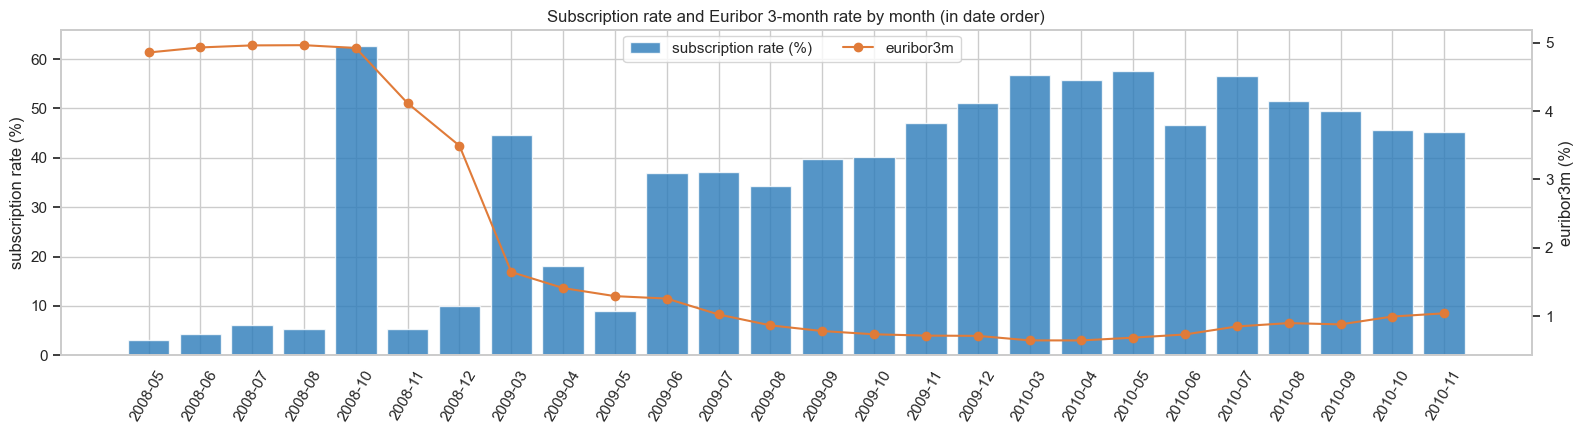

,n,rate,euribor3m,nr_employed
eda_period,,,,
2008-05,7763,3.09,4.857663,5191.0
2008-06,4374,4.30,4.931639,5228.1
2008-07,6685,6.09,4.961587,5228.1
2008-08,5175,5.24,4.964804,5228.1
2008-10,67,62.69,4.923776,5195.8
2008-11,3616,5.25,4.114895,5195.8
2008-12,10,10.00,3.493400,5176.3
2009-03,282,44.68,1.646220,5099.1
2009-04,2458,17.98,1.411722,5099.1


In [25]:
by_period = (df.groupby("eda_period", sort=False)
             .agg(n=("y_num", "size"), rate=("y_num", "mean"),
                  euribor3m=("euribor3m", "mean"), nr_employed=("nr.employed", "mean"))
             .assign(rate=lambda t: (100 * t["rate"]).round(2)))

fig, ax1 = plt.subplots(figsize=(16, 4.5))
ax1.bar(by_period.index, by_period["rate"], color="#2b7bba", alpha=0.8, label="subscription rate (%)")
ax1.set_ylabel("subscription rate (%)")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(by_period.index, by_period["euribor3m"], color="#e07b39", marker="o", label="euribor3m")
ax2.set_ylabel("euribor3m (%)")
ax2.grid(False)
ax1.set_title("Subscription rate and Euribor 3-month rate by month (in date order)")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2)
save_fig("fig09_time_pattern")
by_period

In [26]:
rate_by_year = df.groupby("eda_year")["y_num"].agg(n="size", rate="mean")
rate_by_year["rate"] = (100 * rate_by_year["rate"]).round(2)
rate_by_year

,n,rate
eda_year,,
2008,27690,4.84
2009,11440,19.48
2010,2058,52.14


## 11. Leakage evidence: `duration`
The documentation warns that `duration` is only known **after** the call. If it is very strongly predictive,
including it would inflate results in a way that cannot be reproduced when ranking clients *before* calling them.

Single-feature ROC-AUC of duration:            0.818
Best single-feature ROC-AUC of any other input: 0.749 (nr.employed)
Calls with duration = 0: 4, of which subscribed: 0


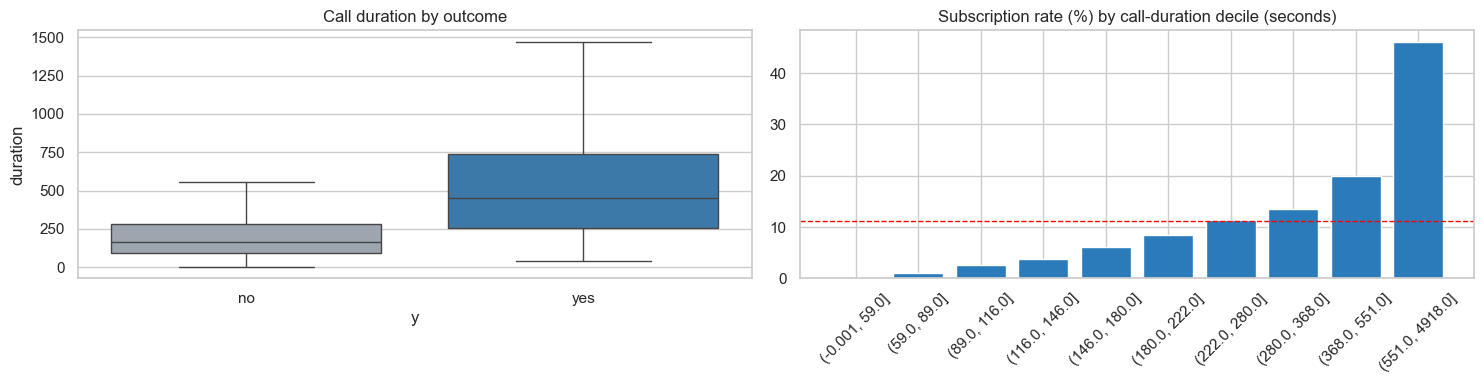

,n,subscribed,rate,lift_vs_overall
duration,,,,
"(-0.001, 59.0]",4181,1,0.02,0.00
"(59.0, 89.0]",4207,43,1.02,0.09
"(89.0, 116.0]",3987,107,2.68,0.24
"(116.0, 146.0]",4152,157,3.78,0.34
"(146.0, 180.0]",4178,256,6.13,0.54
"(180.0, 222.0]",4096,346,8.45,0.75
"(222.0, 280.0]",4062,463,11.40,1.01
"(280.0, 368.0]",4103,554,13.50,1.20
"(368.0, 551.0]",4118,824,20.01,1.78


In [27]:
auc_duration = roc_auc_score(df["y_num"], df["duration"])
other_aucs = assoc_num.drop(index="duration")["auc_strength"]
print(f"Single-feature ROC-AUC of duration:            {auc_duration:.3f}")
print(f"Best single-feature ROC-AUC of any other input: {other_aucs.max():.3f} ({other_aucs.idxmax()})")
print(f"Calls with duration = 0: {(df['duration'] == 0).sum()}, of which subscribed: "
      f"{df.loc[df['duration'] == 0, 'y_num'].sum()}")

dur_bins = pd.qcut(df["duration"], q=10, duplicates="drop")
dur_rates = rate_table(dur_bins)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=df, x=config.TARGET, y="duration", hue=config.TARGET, order=["no", "yes"],
            palette={"no": "#9aa5b1", "yes": "#2b7bba"}, legend=False, showfliers=False, ax=axes[0])
axes[0].set_title("Call duration by outcome")
axes[1].bar(dur_rates.index.astype(str), dur_rates["rate"], color="#2b7bba")
axes[1].axhline(100 * OVERALL_RATE, color="red", ls="--", lw=1)
axes[1].set_title("Subscription rate (%) by call-duration decile (seconds)")
axes[1].tick_params(axis="x", rotation=45)
save_fig("fig10_duration_leakage")
dur_rates

## 12. Summary of findings
Full details, evidence and implications: `docs/eda_findings.txt` and `docs/eda_insight_log.md`.

**Data and target**
- 41,188 rows × 21 columns; one row = one client contact record in a campaign (last contact). There is **no client ID**, so repeat clients cannot be identified.
- Target is **imbalanced: 11.27% yes (7.9 : 1)**. "Always no" gets 88.7% accuracy but finds no subscribers, so **accuracy must not be the main metric**; use PR-AUC, recall/precision/F1 for `yes`, ROC-AUC.

**Data quality**
- No blank cells, but **26% of rows contain at least one `"unknown"`**. `default` is 20.9% unknown, and unknown-default clients subscribe at only 5.2% vs 12.9%, so **"unknown" is informative and should stay a category**, not be imputed.
- `default = yes` occurs only **3 times**, so `default` is effectively *no vs unknown*.
- `housing` and `loan` are "unknown" on exactly the same 990 rows.
- **12 exact duplicate rows**, with no conflicting labels.
- `pdays = 999` (96.3% of rows) is a placeholder. **4,110 rows have `pdays = 999` but `previous > 0`** (all `poutcome = failure`), which contradicts the documentation; `previous`/`poutcome` are more reliable indicators of prior contact.
- Outliers in `age`, `campaign`, `previous` are real and informative (see Section 5), so **none are removed**.

**Strongest signals (pre-call information)**
- **Previous campaign success:** `poutcome = success` gives 65.1% (5.8× overall), the strongest categorical association (Cramér's V 0.32).
- **Economic context:** `nr.employed`, `euribor3m`, `emp.var.rate` are the strongest numeric predictors (single-feature AUC 0.72–0.75). Subscriptions are higher when rates and employment are low.
- **Timing:** month (V 0.27). Mar, Sep, Oct, Dec have rates of 44–51%, but only 2,016 rows in total; May has the most calls (13,769) and the lowest rate (6.4%).
- **Channel:** cellular 14.7% vs telephone 5.2%.
- **Client profile:** students (31.4%) and retired (25.2%); age is **U-shaped** (17–25: 21%, 61+: 43–48%, 41–50: 8%), a non-linear pattern that a single linear age term cannot capture.
- **Contact fatigue:** 1 call 13.0% falling to 3.6% at 10+ calls.
- **Weak / no signal:** `housing` (p = 0.058) and `loan` (p = 0.58) show no meaningful association; `day_of_week` is very weak (V 0.025).

**Modelling risks**
- **Severe multicollinearity:** VIF `euribor3m` 64, `emp.var.rate` 33, `nr.employed` 32 (Spearman ρ ≈ 0.93–0.94). This is a problem for Logistic Regression coefficients, not for tree models.
- **Strong time drift:** the yes-rate rises from **4.8% (2008) to 19.5% (2009) to 52.1% (2010)** while call volume falls (27,690 → 2,058 rows). Month and the economic indicators partly act as a proxy for this period. This affects validation design (random vs time-based split) and how far results generalise.
- **`duration` confirmed as leakage:** single-feature AUC 0.818 (higher than any pre-call feature); the shortest-call decile has 0.02% yes vs 46% for the longest. It is excluded from the realistic model (decision D3).